In [14]:
import gymnasium as gym

%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [71]:
import importlib
from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep


importlib.reload(racetrack)

env = RacetrackEnv()
observation, info = env.reset()
total_reward, done = 0, False
episodes = 0
while episodes != 1000:
    action = env.action_space.sample()  # replace with a policy
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    done = terminated or truncated
    # Uncomment to get a visual of the car traveling
    clear_output(wait=True)
    sleep(1)
    print(env.render())
    if done:
        if episodes % 100 == 0:
            print(f"Finished iteration {episodes}")
        episodes += 1
        env.reset()

print("Return:", total_reward, info)

KeyboardInterrupt: 

### Racetrack position heatmap

Runs many episodes under a random policy and counts how often each `(x, y)` cell is
visited, then plots it with `seaborn.heatmap` (the same plotting call used for
confusion matrices). Off-track cells are masked out so only the track itself is shown.

soft reset, starting at (5, 0)
doing path
vx: 0 vy:1 x0 5 y0 0
doing path
vx: -1 vy:2 x0 5 y0 1
doing path
vx: -2 vy:3 x0 4 y0 3
doing path
vx: -2 vy:4 x0 2 y0 6
doing path
vx: -3 vy:4 x0 0 y0 10
doing path
vx: -3 vy:4 x0 0 y0 10
doing path
vx: -3 vy:4 x0 0 y0 10
doing path
vx: -3 vy:4 x0 0 y0 10
doing path
vx: -2 vy:4 x0 0 y0 10
doing path
vx: -3 vy:4 x0 0 y0 11
doing path
vx: -3 vy:4 x0 0 y0 11
doing path
vx: -2 vy:3 x0 0 y0 11
doing path
vx: -2 vy:4 x0 0 y0 11
doing path
vx: -2 vy:4 x0 0 y0 12
doing path
vx: -3 vy:4 x0 0 y0 13
doing path
vx: -2 vy:4 x0 0 y0 13
doing path
vx: -3 vy:4 x0 0 y0 14
doing path
vx: -2 vy:4 x0 0 y0 14
doing path
vx: -1 vy:4 x0 0 y0 15
doing path
vx: -2 vy:4 x0 0 y0 17
doing path
vx: -2 vy:4 x0 0 y0 18
doing path
vx: -3 vy:4 x0 0 y0 19
doing path
vx: -3 vy:4 x0 0 y0 19
doing path
vx: -4 vy:4 x0 0 y0 19
doing path
vx: -4 vy:4 x0 0 y0 19
doing path
vx: -3 vy:4 x0 0 y0 19
doing path
vx: -3 vy:3 x0 0 y0 19
doing path
vx: -3 vy:2 x0 0 y0 19
doing path
vx: -4 vy:1

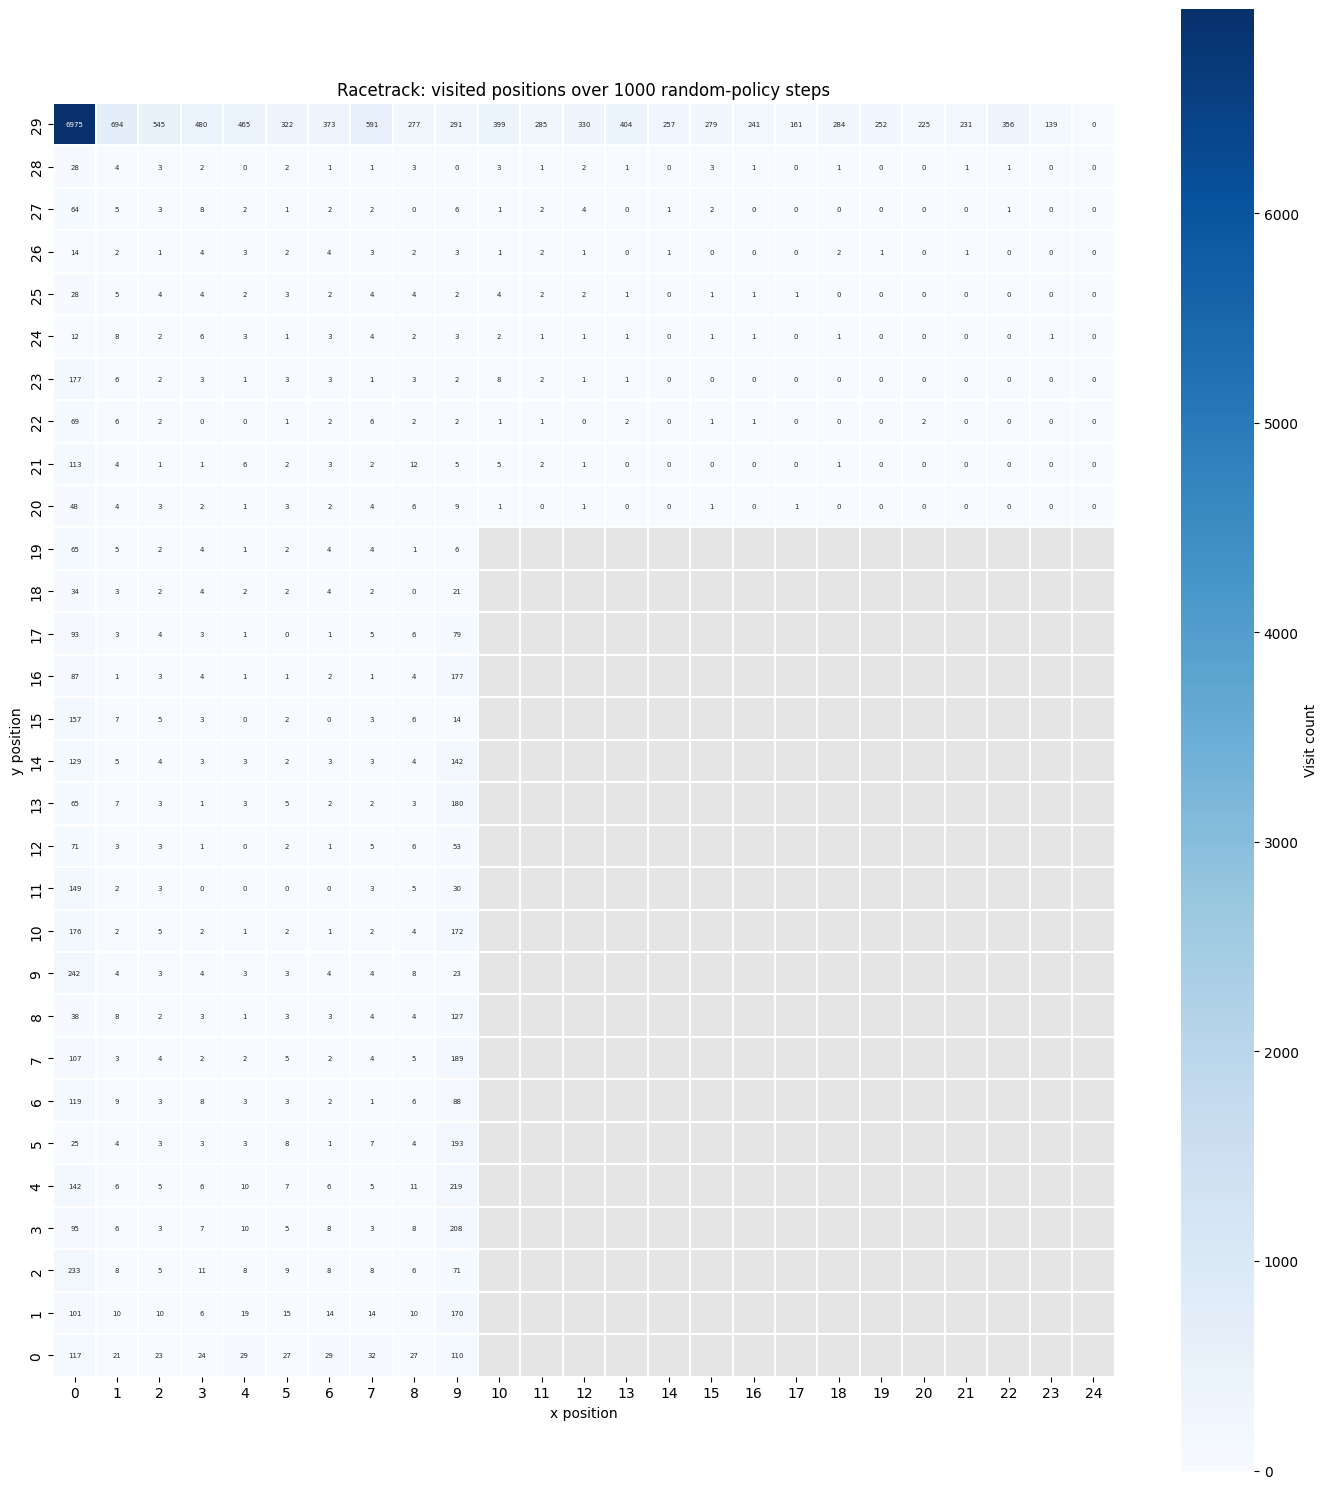

{'finished': 100, 'crashed': 0}


In [69]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from racetrack import RacetrackEnv

track_env = RacetrackEnv()
n_steps = 1000
visits = np.zeros((track_env.height, track_env.width), dtype=int)

track_env.reset()

episode_results = {
    "finished": 0,
    "crashed": 0
}
episodes = 0
while episodes != 100:
    x, y = track_env.pos
    visits[y, x] += 1
    action = track_env.action_space.sample()
    observation, reward, terminated, truncated, info = track_env.step(action)
    done = terminated or truncated
    if done:
        if info["finished"]:
            episode_results["finished"] += 1
            episodes += 1
            track_env.reset()

mask = ~track_env.track
fig, ax = plt.subplots(figsize=(14, 15))
sns.heatmap(
    visits.astype(float),
    mask=mask,
    cmap="Blues",
    annot=True,
    fmt=".0f",
    annot_kws={"size": 5},
    cbar_kws={"label": "Visit count"},
    linewidths=0.1,
    linecolor="white",
    square=True,
    ax=ax,
)
ax.set_facecolor("#e5e5e5")
ax.invert_yaxis()
ax.set_xlabel("x position")
ax.set_ylabel("y position")
ax.set_title(f"Racetrack: visited positions over {n_steps} random-policy steps")
plt.tight_layout()
plt.show()
print(episode_results)

# Solving Markov Decision Problems via Monte Carlo & SARSA

In [68]:
class agent_monte_carlo:
    '''A class to manage the agent'''
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config
        self.z_map = {}
        self.q_map = {}

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def update_Q(self,trajectory):
        """
        trajectory is stored as (x, y, vx, vy, action, reward)
        """
        T = len(trajectory)
        y_discount = self.config["discount"]
        
        G = 0
        visited_state_actions = set()
        for t in reversed(range(T - 1)):
            s_t = trajectory[t][:4]
            a_t = trajectory[t][4]
            r_t = trajectory[t + 1][5]
            G = r_t + y_discount*G
            for t_prime in range(t - 1):
                s_t_prime = trajectory[t_prime][:4]
                a_t_prime = trajectory[t_prime][4]
                    
                state_action_pair = (s_t_prime, a_t_prime)
                if state_action_pair not in visited_state_actions:
                    visited_state_actions.add(state_action_pair)
                    if state_action_pair not in self.z_map:
                        self.z_map[state_action_pair] = []
                    self.z_map[state_action_pair].append(G)
                    self.q_map[state_action_pair] = sum(self.z_map[state_action_pair]) / len(self.z_map[state_action_pair])
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def pi(self,state,epsilon):
        n_actions = 9
        
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        best_action = np.random.choice(best_actions)
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        
        probs[best_action] += (1.0 - epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

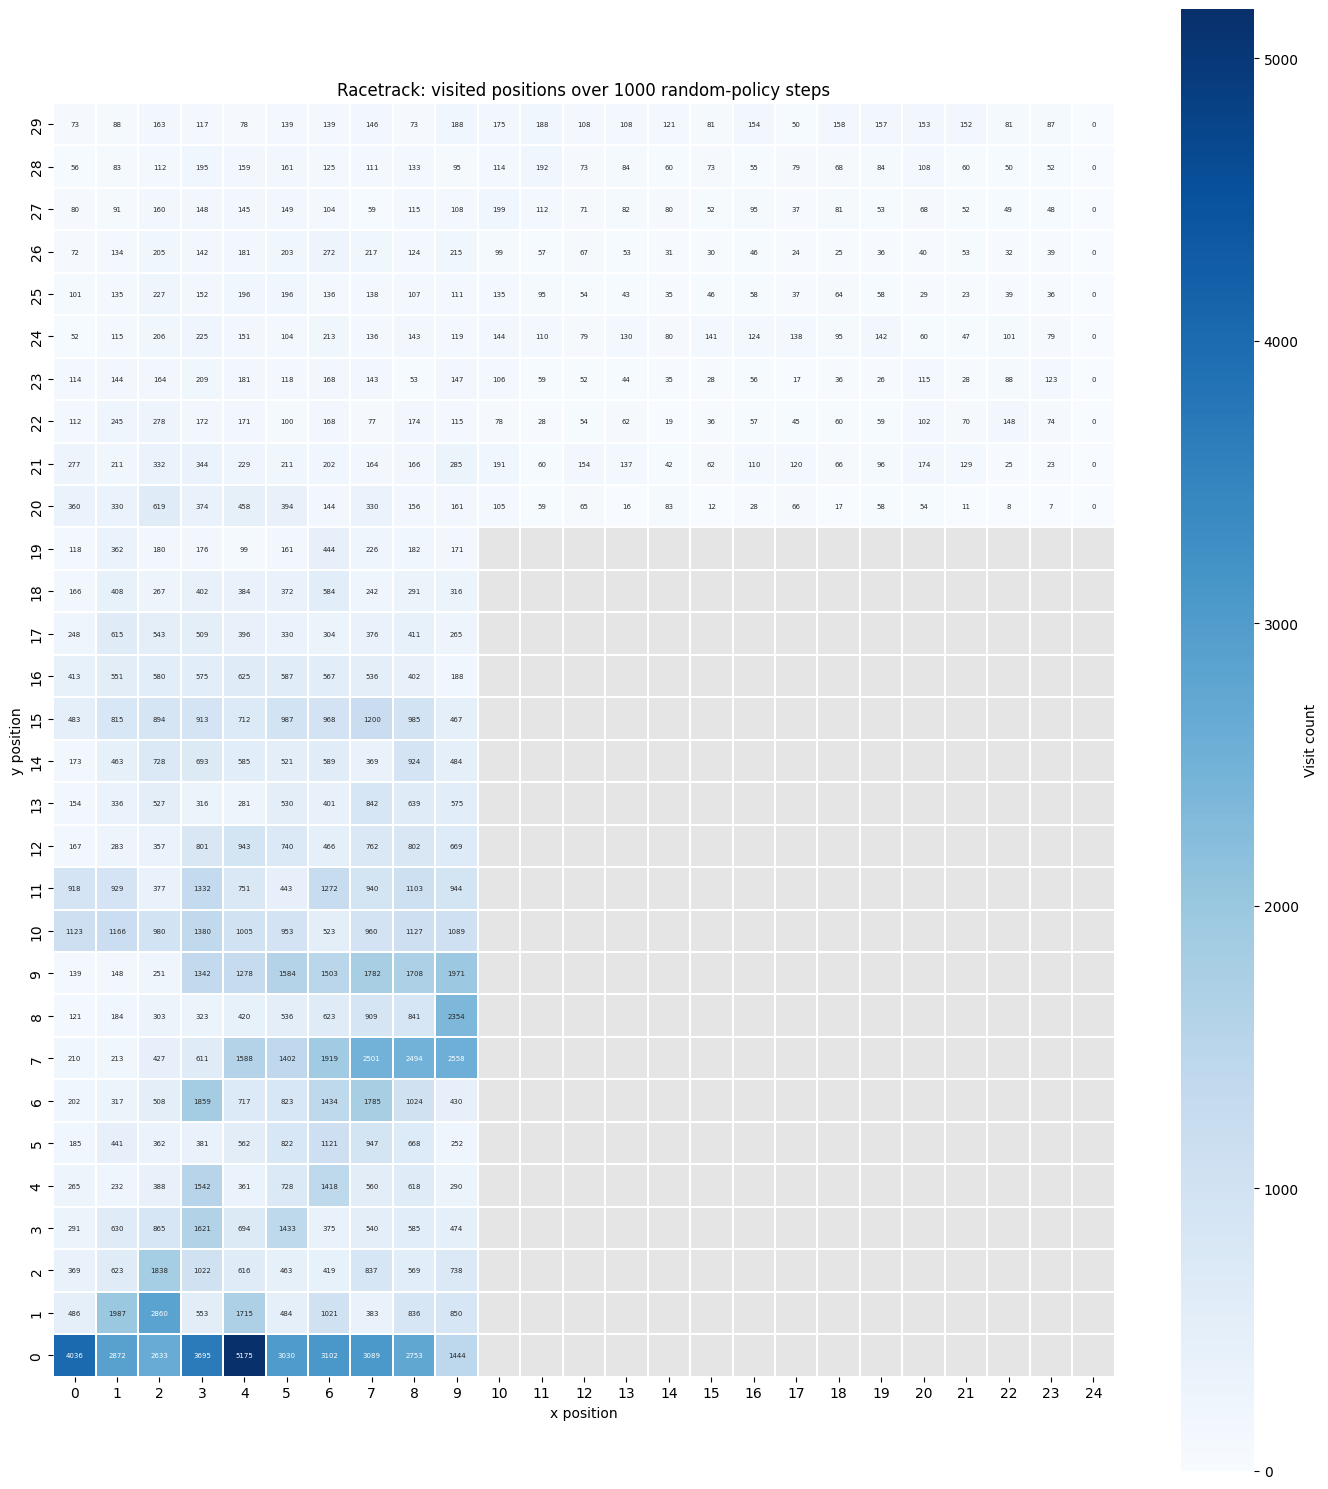

{'finished': 572, 'crashed': 9428, 'episode_lengths': [19, 20, 30, 37, 21, 25, 24, 50, 40, 26, 40, 42, 37, 37, 20, 24, 36, 35, 26, 25, 28, 26, 71, 23, 17, 36, 31, 26, 23, 30, 30, 50, 30, 29, 25, 37, 33, 30, 36, 45, 34, 31, 31, 34, 38, 56, 53, 24, 30, 42, 34, 43, 26, 33, 29, 48, 31, 28, 42, 52, 30, 28, 47, 47, 51, 47, 24, 34, 37, 42, 41, 31, 32, 16, 40, 49, 44, 21, 62, 26, 35, 38, 32, 35, 37, 27, 24, 41, 52, 23, 33, 44, 34, 22, 53, 45, 42, 46, 23, 22, 43, 22, 34, 33, 44, 25, 48, 23, 31, 34, 39, 48, 36, 44, 43, 46, 37, 45, 24, 43, 27, 24, 48, 50, 35, 48, 42, 48, 24, 34, 29, 31, 38, 30, 24, 37, 28, 32, 39, 28, 29, 39, 25, 37, 21, 29, 37, 40, 25, 34, 54, 38, 41, 50, 32, 26, 35, 30, 37, 53, 48, 46, 24, 51, 32, 33, 64, 53, 20, 36, 32, 33, 50, 28, 18, 41, 58, 28, 33, 39, 30, 43, 44, 38, 41, 43, 33, 33, 58, 36, 34, 49, 31, 32, 39, 41, 49, 27, 58, 32, 51, 44, 46, 53, 45, 66, 49, 25, 40, 53, 55, 21, 38, 47, 52, 28, 41, 34, 35, 43, 65, 57, 41, 22, 31, 43, 41, 36, 48, 31, 27, 67, 19, 39, 43, 42, 4

In [69]:
import importlib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep

agent = agent_monte_carlo({
    "discount": 0.9
})


track_env = RacetrackEnv(soft_reset=True)
visits = np.zeros((track_env.height, track_env.width), dtype=int)

track_env.reset()

episode_results = {
    "finished": 0,
    "crashed": 0,
    "episode_lengths": [],
    "rewards": []
}
episodes = 0
epsilon = 0.1

while episodes != 10000:
    if episodes >= 8000:
        epsilon = 0.1
    elif episodes >= 5000:
        epsilon = 0.3
    elif episodes >= 3000:
        epsilon = 0.5
    trajectory = []
    done = False
    action_set = set()
    clear_output(wait=True)
    if episodes % 100 == 0:
        print(f"Episode {episodes}")
    while not done:
        x, y = track_env.pos
        vx, vy = track_env.vel
        state = (x, y, vx, vy)
        visits[y, x] += 1
        # sleep(0.01)
        # clear_output(wait=True)
        # print(track_env.render())
        action = agent.pi(state, epsilon)
        action_set.add(action)

        observation, reward, terminated, truncated, info = track_env.step(action)
        crashed = info.get("crashed", None)
        done = terminated or truncated
        
        # Record the step into the trajectory list
        trajectory.append((x, y, vx, vy, action, reward))
        
    if info["finished"]:
        episode_results["finished"] += 1
        episode_results["episode_lengths"].append(track_env.steps)
    else:
        episode_results["crashed"] += 1
    episode_results["rewards"].append(reward)

    episodes += 1
    track_env.reset()
    agent.update_Q(trajectory)

mask = ~track_env.track
fig, ax = plt.subplots(figsize=(14, 15))
sns.heatmap(
    visits.astype(float),
    mask=mask,
    cmap="Blues",
    annot=True,
    fmt=".0f",
    annot_kws={"size": 5},
    cbar_kws={"label": "Visit count"},
    linewidths=0.1,
    linecolor="white",
    square=True,
    ax=ax,
)
ax.set_facecolor("#e5e5e5")
ax.invert_yaxis()
ax.set_xlabel("x position")
ax.set_ylabel("y position")
ax.set_title(f"Racetrack: visited positions over {n_steps} random-policy steps")
plt.tight_layout()
plt.show()
print(episode_results)

In [70]:
def print_episode_results(results):
    print(f"finished: {results['finished']}")
    print(f"crashed: {results['crashed']}")
    print(f"average_episode_length: {sum(results['episode_lengths'])/len(results['episode_lengths'])}")
    print(f"average_reward: {sum(results['rewards'])/len(results['rewards'])}")
print_episode_results(episode_results)

finished: 572
crashed: 9428
average_episode_length: 41.03321678321678
average_reward: 0.11487623720926395


In [ ]:
import numpy as np

class agent_sarsa:
    '''A class to manage the agent'''
    
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config
        self.q_map = {}
        self.current_state = config["state"]
        self.current_action = config["action"]

    def update_Q(self, trajectory, done):
        """
        trajectory is stored as (x, y, vx, vy, action, reward)
        """
        state_prime = trajectory[:4]
        action_prime = trajectory[4]
        reward = trajectory[5]
        
        state_action_pair = (self.current_state, self.current_action)
        state_action_prime_pair = (state_prime, action_prime)
        
        alpha = self.config["alpha"]
        y_discount = self.config["discount"]

        q_map_value = self.q_map.get(state_action_pair, 0)
        if done:
            q_map_prime_value = 0
        else:
            state_action_prime_pair = (state_prime, action_prime)
            q_map_prime_value = self.q_map.get(state_action_prime_pair, 0)
        q_map_prime_value = self.q_map.get(state_action_prime_pair, 0)
        
        # SARSA update rule
        self.q_map[state_action_pair] = q_map_value + alpha * (reward + y_discount * q_map_prime_value - q_map_value)
        
        # --- CRITICAL FIX: SHIFT STATE AND ACTION FORWARD ---
        self.current_state = state_prime
        self.current_action = action_prime

    def pi(self, state, epsilon):
        n_actions = self.config.get("n_actions", 9)
        
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        best_action = np.random.choice(best_actions)
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        probs[best_action] += (1.0 - epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

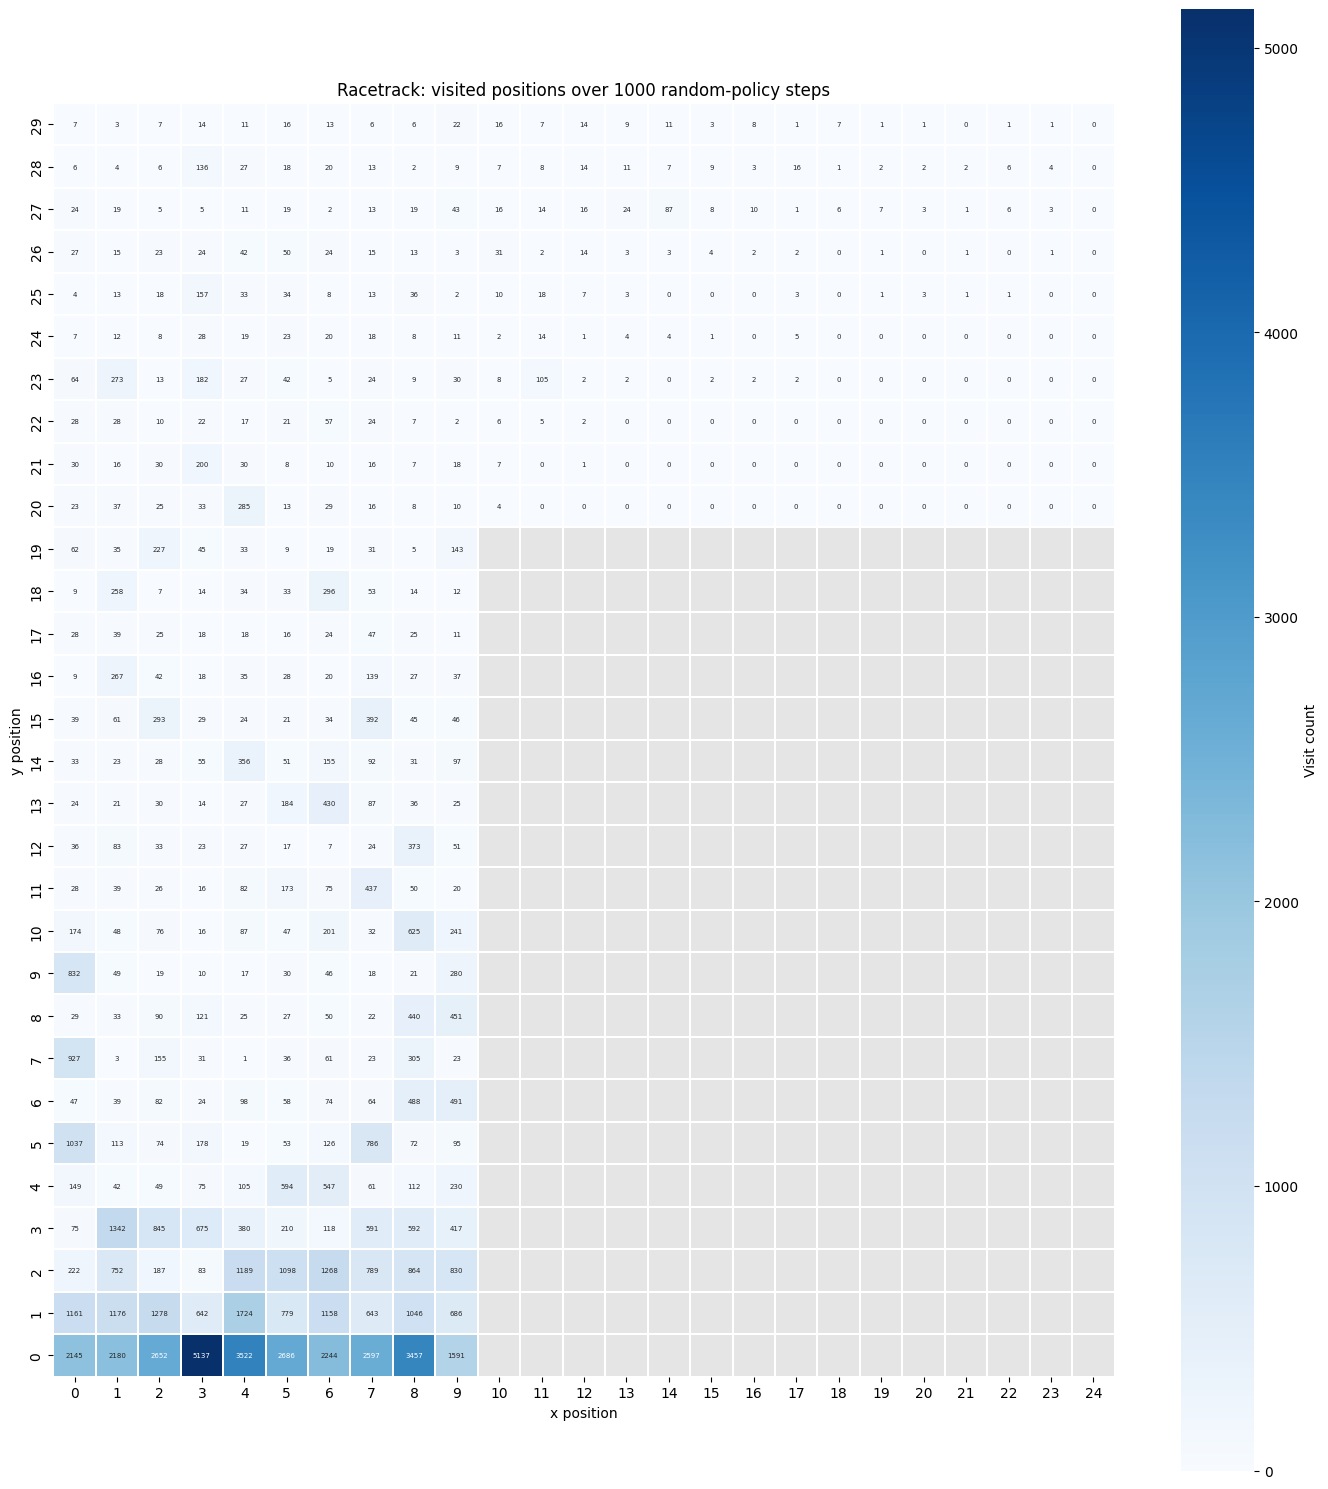

In [78]:
import importlib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep

agent = agent_sarsa({
    "discount": 0.9,
    "state": (0,0,0,0),
    "action": 0,
    "alpha": 0.1
})


track_env = RacetrackEnv(soft_reset=True)
n_steps = 1000
visits = np.zeros((track_env.height, track_env.width), dtype=int)

track_env.reset()

episode_results = {
    "finished": 0,
    "crashed": 0,
    "episode_lengths": [],
    "rewards": []
}
episodes = 0
epsilon = 0.1

while episodes != 10000:
    action = agent.pi(state, epsilon)
    total_episode_reward = 0
    agent.current_state = state
    agent.current_action = action
    
    done = False
    action_set = set()
    clear_output(wait=True)
    if episodes % 100 == 0:
        print(f"Episode {episodes}")
    while not done:
        x, y = track_env.pos
        vx, vy = track_env.vel
        state = (x, y, vx, vy)
        visits[y, x] += 1

        observation, reward, terminated, truncated, info = track_env.step(action)
        done = terminated or truncated
        total_episode_reward += reward
        
        next_x, next_y = track_env.pos
        next_vx, next_vy = track_env.vel
        next_state = (next_x, next_y, next_vx, next_vy)
        
        if not done:
            next_action = agent.pi(next_state, epsilon)
        else:
            next_action = 0  # Dummy action if terminal
            
        step_data = (next_x, next_y, next_vx, next_vy, next_action, reward)
        
        agent.update_Q(step_data, done)
        
        state = next_state
        action = next_action
        x, y, vx, vy = next_x, next_y, next_vx, next_vy
    if info["finished"]:
        episode_results["finished"] += 1
        episode_results["episode_lengths"].append(track_env.steps)
    else:
        episode_results["crashed"] += 1
    episode_results["rewards"].append(reward)
    episodes += 1
    track_env.reset()

mask = ~track_env.track
fig, ax = plt.subplots(figsize=(14, 15))
sns.heatmap(
    visits.astype(float),
    mask=mask,
    cmap="Blues",
    annot=True,
    fmt=".0f",
    annot_kws={"size": 5},
    cbar_kws={"label": "Visit count"},
    linewidths=0.1,
    linecolor="white",
    square=True,
    ax=ax,
)
ax.set_facecolor("#e5e5e5")
ax.invert_yaxis()
ax.set_xlabel("x position")
ax.set_ylabel("y position")
ax.set_title(f"Racetrack: visited positions over {n_steps} random-policy steps")
plt.tight_layout()
plt.show()


In [73]:
print_episode_results(episode_results)

finished: 20
crashed: 9980
average_episode_length: 25.65
average_reward: 0.2700108532043815


In [ ]:
import importlib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep

# 1. Include n_actions in the agent config
agent = agent_sarsa({
    "discount": 0.9,
    "state": (0, 0, 0, 0),
    "action": 0,
    "alpha": 0.1,
    "n_actions": 9
})

track_env = RacetrackEnv(soft_reset=True)
n_steps = 1000
visits = np.zeros((track_env.height, track_env.width), dtype=int)

episode_results = {
    "finished": 0,
    "crashed": 0,
    "episode_lengths": [],
    "rewards": []
}
episodes = 0
epsilon = 0.8

while episodes != 10000:
    if episodes >= 8000:
        epsilon = 0.1
    elif episodes >= 5000:
        epsilon = 0.3
    elif episodes >= 3000:
        epsilon = 0.5
        
    if episodes % 100 == 0:
        print(f"Episode {episodes}")
        
    # Reset environment and get initial state
    obs, info = track_env.reset()
    x, y = track_env.pos
    vx, vy = track_env.vel
    state = (x, y, vx, vy)
    
    # 2. Choose the initial action a for the episode
    action = agent.pi(state, epsilon)
    
    # Initialize agent's internal state/action trackers
    agent.current_state = state
    agent.current_action = action
    
    done = False
    total_episode_reward = 0
    
    while not done:
        visits[y, x] += 1
        
        observation, reward, terminated, truncated, info = track_env.step(action)
        done = terminated or truncated
        total_episode_reward += reward
        
        next_x, next_y = track_env.pos
        next_vx, next_vy = track_env.vel
        next_state = (next_x, next_y, next_vx, next_vy)
        
        if not done:
            next_action = agent.pi(next_state, epsilon)
        else:
            next_action = 0  # Dummy action if terminal
            
        step_data = (next_x, next_y, next_vx, next_vy, next_action, reward)
        
        agent.update_Q(step_data, done)
        
        state = next_state
        action = next_action
        x, y, vx, vy = next_x, next_y, next_vx, next_vy

    # Record metrics at the end of the episode
    if info.get("finished", False):
        episode_results["finished"] += 1
        episode_results["episode_lengths"].append(track_env.steps)
    else:
        episode_results["crashed"] += 1
        
    episode_results["rewards"].append(total_episode_reward)
    episodes += 1

print("Training finished!")

# Plotting heatmap results
mask = ~track_env.track
fig, ax = plt.subplots(figsize=(14, 15))
sns.heatmap(
    visits.astype(float),
    mask=mask,
    cmap="Blues",
    annot=True,
    fmt=".0f",
    annot_kws={"size": 5},
    cbar_kws={"label": "Visit count"},
    linewidths=0.1,
    linecolor="white",
    square=True,
    ax=ax,
)
ax.set_facecolor("#e5e5e5")
ax.invert_yaxis()
ax.set_xlabel("x position")
ax.set_ylabel("y position")
ax.set_title(f"Racetrack: visited positions over SARSA training episodes")
plt.tight_layout()
plt.show()

In [77]:
print_episode_results(episode_results)

finished: 24
crashed: 9976
average_episode_length: 24.083333333333332
average_reward: 0.32469082591790366
